# Member A: Ensemble Classification on CTG Dataset
## Random Forest, AdaBoost, and Gradient Boosting

---

### Project & Member Allocation
- **Track:** Multi-Class Classification (Fetal State: Normal, Suspect, Pathologic)
- **Dataset:** UCI Cardiotocography (CTG) Dataset (`CTG.xls`)
- **Allocated Member:** **Member A**
- **Allocated Algorithms:**
  1. **Random Forest Classifier** (Bagging & Feature Subspace Ensemble)
  2. **AdaBoost Classifier** (Adaptive Boosting Sequential Ensemble)
  3. **Gradient Boosting Classifier** (Gradient-Guided Loss Optimization Ensemble)
- **Role / Tasks:** End-to-end implementation, baseline evaluation, systematic hyperparameter tuning using 5-fold cross-validation, feature importance extraction, and multi-metric comparative analysis across all three ensemble models.

---

## 1. Setup & Environment Imports
Import essential packages for data manipulation, visualization, ensemble learning, and classification performance evaluation.

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.ensemble import (
    RandomForestClassifier,
    AdaBoostClassifier,
    GradientBoostingClassifier
)
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report,
    confusion_matrix
)

# Set visualization styles
sns.set_theme(style="whitegrid")
plt.rcParams["font.sans-serif"] = "DejaVu Sans"
%matplotlib inline

## 2. Data Loading & Preprocessing

The Cardiotocography (CTG) dataset contains 2,126 fetal cardiotocograms categorized into three fetal states:
- **1 — Normal**
- **2 — Suspect**
- **3 — Pathologic**

Following the capstone classification pipeline:
1. Missing records in target `NSP` are removed.
2. The 21 standard morphological and clinical features are selected.
3. The dataset is split into 80% training and 20% test sets using a stratified split (`random_state=42`).
4. Tree-based ensemble methods are invariant to monotonic feature scaling; hence unscaled features are supplied directly to maintain clean interpretability and consistency with the main classification workflow.

In [2]:
# Resolve path whether run from repo root or team_contribution/
data_path = "../data/CTG.xls" if os.path.exists("../data/CTG.xls") else "data/CTG.xls"
df = pd.read_excel(data_path, sheet_name="Raw Data")

# Drop rows missing the target variable NSP
df = df.dropna(subset=["NSP"]).copy()

# 21 CTG feature columns
feature_columns = [
    "LB", "AC", "FM", "UC", "ASTV", "MSTV", "ALTV", "MLTV",
    "DL", "DS", "DP", "Width", "Min", "Max", "Nmax", "Nzeros",
    "Mode", "Mean", "Median", "Variance", "Tendency"
]

X = df[feature_columns]
y = df["NSP"].astype(int)

class_names = {1: "Normal", 2: "Suspect", 3: "Pathologic"}

# Stratified 80/20 train/test split matching classification.ipynb
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print(f"Total cleaned observations : {len(df)}")
print(f"Number of features         : {X.shape[1]}")
print(f"Training set observations  : {X_train.shape[0]}")
print(f"Testing set observations   : {X_test.shape[0]}")
print("\nTarget class distribution in test set:")
for code, name in class_names.items():
    count = (y_test == code).sum()
    pct = count / len(y_test) * 100
    print(f"  Class {code} ({name:10s}): {count:3d} ({pct:.2f}%)")

Total cleaned observations : 2126
Number of features         : 21
Training set observations  : 1700
Testing set observations   : 426

Target class distribution in test set:
  Class 1 (Normal    ): 332 (77.93%)
  Class 2 (Suspect   ):  59 (13.85%)
  Class 3 (Pathologic):  35 (8.22%)


---
## 3. Algorithm 1: Random Forest Classifier

### Concept & Methodology
Random Forest is a bagging (Bootstrap Aggregating) ensemble that constructs a forest of decision trees. Each tree is trained on a bootstrap sample of the training data, and at each split point, only a random subset of features is considered. This decorrelates individual trees and dramatically reduces overall model variance without inflating bias.

### Baseline Training & Evaluation

In [3]:
# Baseline Random Forest model (100 estimators)
rf = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

rf.fit(X_train, y_train)

y_pred_rf = rf.predict(X_test)
y_prob_rf = rf.predict_proba(X_test)

accuracy_rf = accuracy_score(y_test, y_pred_rf)
precision_rf = precision_score(y_test, y_pred_rf, average="weighted", zero_division=0)
recall_rf = recall_score(y_test, y_pred_rf, average="weighted", zero_division=0)
f1_rf = f1_score(y_test, y_pred_rf, average="weighted", zero_division=0)
roc_auc_rf = roc_auc_score(y_test, y_prob_rf, multi_class="ovr", average="weighted")

print("Random Forest Classifier (Baseline)")
print("===================================")
print(f"Accuracy : {accuracy_rf:.4f}")
print(f"Precision: {precision_rf:.4f}")
print(f"Recall   : {recall_rf:.4f}")
print(f"F1 Score : {f1_rf:.4f}")
print(f"ROC-AUC  : {roc_auc_rf:.4f}")

Random Forest Classifier (Baseline)
Accuracy : 0.9296
Precision: 0.9267
Recall   : 0.9296
F1 Score : 0.9263
ROC-AUC  : 0.9830


Random Forest (Baseline) Classification Report:
------------------------------------------------
              precision    recall  f1-score   support

      Normal       0.95      0.98      0.96       332
     Suspect       0.85      0.66      0.74        59
  Pathologic       0.86      0.89      0.87        35

    accuracy                           0.93       426
   macro avg       0.89      0.84      0.86       426
weighted avg       0.93      0.93      0.93       426



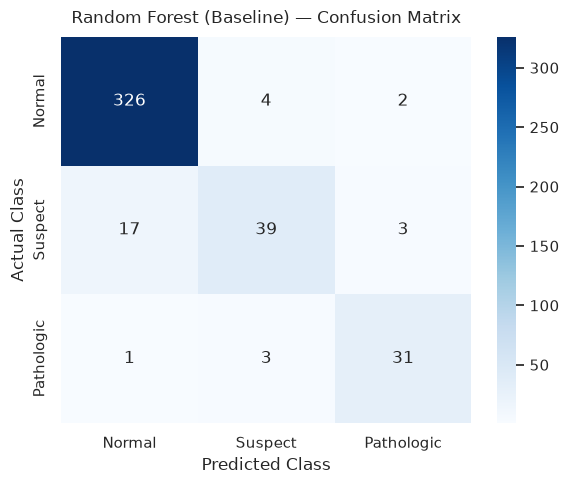

In [4]:
print("Random Forest (Baseline) Classification Report:")
print("------------------------------------------------")
print(
    classification_report(
        y_test,
        y_pred_rf,
        target_names=["Normal", "Suspect", "Pathologic"],
        zero_division=0
    )
)

cm_rf = confusion_matrix(y_test, y_pred_rf)

plt.figure(figsize=(6, 5))
sns.heatmap(
    cm_rf,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Normal", "Suspect", "Pathologic"],
    yticklabels=["Normal", "Suspect", "Pathologic"]
)
plt.title("Random Forest (Baseline) — Confusion Matrix", fontsize=12, pad=10)
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")
plt.tight_layout()
plt.show()

### Random Forest Hyperparameter Tuning
We optimize the number of trees (`n_estimators` ∈ [50, 100, 150, 200, 300]) using `GridSearchCV` with 5-fold cross-validation and weighted F1-score optimization.

In [5]:
param_grid_rf = {
    "n_estimators": [50, 100, 150, 200, 300]
}

rf_base = RandomForestClassifier(random_state=42)

rf_grid = GridSearchCV(
    estimator=rf_base,
    param_grid=param_grid_rf,
    cv=5,
    scoring="f1_weighted",
    n_jobs=-1
)

rf_grid.fit(X_train, y_train)

print("Random Forest Tuning Results:")
print("-----------------------------")
print("Best Parameters             :", rf_grid.best_params_)
print(f"Best Cross-Validation Score : {rf_grid.best_score_:.4f}")

Random Forest Tuning Results:
-----------------------------
Best Parameters             : {'n_estimators': 200}
Best Cross-Validation Score : 0.9414


In [6]:
best_rf = rf_grid.best_estimator_

y_pred_rf_tuned = best_rf.predict(X_test)
y_prob_rf_tuned = best_rf.predict_proba(X_test)

accuracy_rf_tuned = accuracy_score(y_test, y_pred_rf_tuned)
precision_rf_tuned = precision_score(y_test, y_pred_rf_tuned, average="weighted", zero_division=0)
recall_rf_tuned = recall_score(y_test, y_pred_rf_tuned, average="weighted", zero_division=0)
f1_rf_tuned = f1_score(y_test, y_pred_rf_tuned, average="weighted", zero_division=0)
roc_auc_rf_tuned = roc_auc_score(y_test, y_prob_rf_tuned, multi_class="ovr", average="weighted")

print("Tuned Random Forest Classifier")
print("==============================")
print(f"Best Parameters: {rf_grid.best_params_}")
print(f"Accuracy       : {accuracy_rf_tuned:.4f}")
print(f"Precision      : {precision_rf_tuned:.4f}")
print(f"Recall         : {recall_rf_tuned:.4f}")
print(f"F1 Score       : {f1_rf_tuned:.4f}")
print(f"ROC-AUC        : {roc_auc_rf_tuned:.4f}")

Tuned Random Forest Classifier
Best Parameters: {'n_estimators': 200}
Accuracy       : 0.9319
Precision      : 0.9290
Recall         : 0.9319
F1 Score       : 0.9288
ROC-AUC        : 0.9846


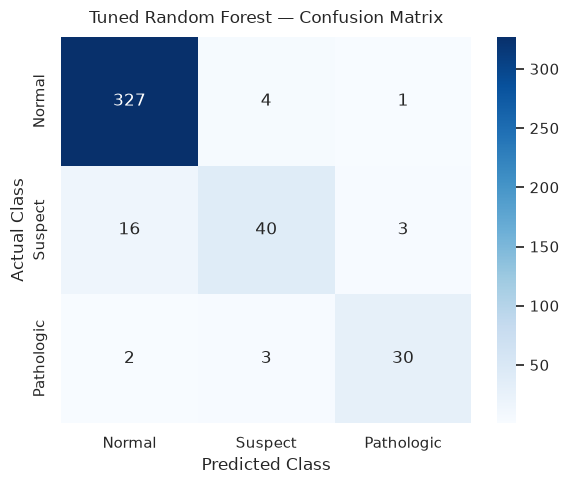

In [7]:
cm_rf_tuned = confusion_matrix(y_test, y_pred_rf_tuned)

plt.figure(figsize=(6, 5))
sns.heatmap(
    cm_rf_tuned,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Normal", "Suspect", "Pathologic"],
    yticklabels=["Normal", "Suspect", "Pathologic"]
)
plt.title("Tuned Random Forest — Confusion Matrix", fontsize=12, pad=10)
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")
plt.tight_layout()
plt.show()

### Random Forest Feature Importance Analysis

Top 10 Most Important Features in Tuned Random Forest:
Feature  Importance
   ASTV    0.145228
   MSTV    0.122153
   ALTV    0.115943
   Mean    0.095061
   Mode    0.057239
     AC    0.051123
   MLTV    0.049197
     DP    0.047619
 Median    0.047255
     UC    0.042752


C:\Users\sivap\AppData\Local\Temp\ipykernel_30680\3504750874.py:10: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=importance_df_rf, x="Importance", y="Feature", palette="Blues_r")


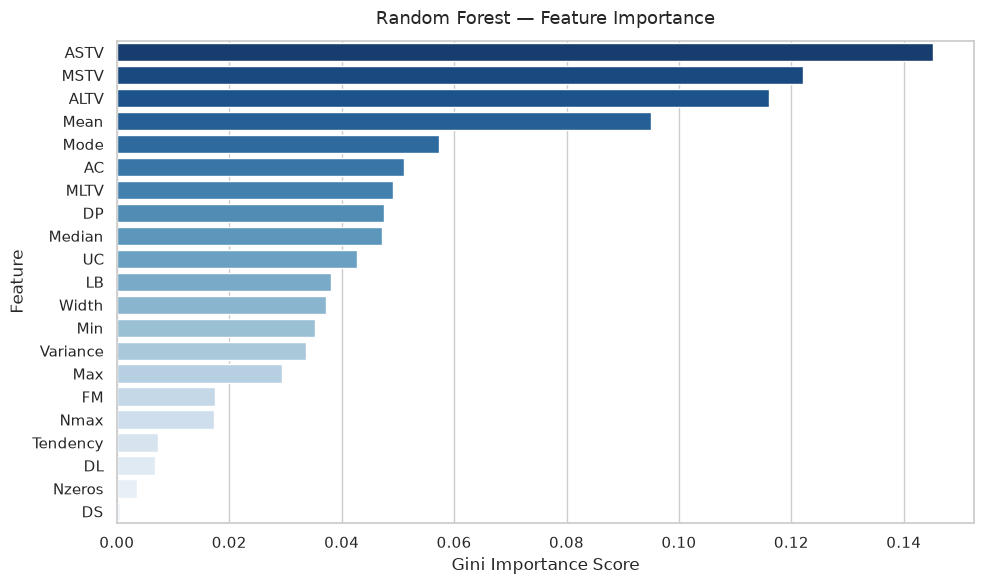

In [8]:
importance_df_rf = pd.DataFrame({
    "Feature": X_train.columns,
    "Importance": best_rf.feature_importances_
}).sort_values(by="Importance", ascending=False)

print("Top 10 Most Important Features in Tuned Random Forest:")
print(importance_df_rf.head(10).to_string(index=False))

plt.figure(figsize=(10, 6))
sns.barplot(data=importance_df_rf, x="Importance", y="Feature", palette="Blues_r")
plt.title("Random Forest — Feature Importance", fontsize=13, pad=12)
plt.xlabel("Gini Importance Score")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()

### Baseline vs Tuned Random Forest Comparison

In [9]:
rf_comparison = pd.DataFrame(
    {
        "Accuracy": [accuracy_rf, accuracy_rf_tuned],
        "Precision": [precision_rf, precision_rf_tuned],
        "Recall": [recall_rf, recall_rf_tuned],
        "F1 Score": [f1_rf, f1_rf_tuned],
        "ROC-AUC": [roc_auc_rf, roc_auc_rf_tuned]
    },
    index=["Baseline Random Forest", "Tuned Random Forest"]
)

rf_comparison.loc["Difference (Tuned - Baseline)"] = (
    rf_comparison.loc["Tuned Random Forest"] - rf_comparison.loc["Baseline Random Forest"]
)
rf_comparison.index.name = "Model Configuration"
display(rf_comparison.round(4))

,Accuracy,Precision,Recall,F1 Score,ROC-AUC
Model Configuration,,,,,
Baseline Random Forest,0.9296,0.9267,0.9296,0.9263,0.9830
Tuned Random Forest,0.9319,0.9290,0.9319,0.9288,0.9846
Difference (Tuned - Baseline),0.0023,0.0023,0.0023,0.0025,0.0016


---
## 4. Algorithm 2: AdaBoost Classifier

### Concept & Methodology
AdaBoost (Adaptive Boosting) is a sequential boosting algorithm. In every iteration, a weak base estimator (by default, a 1-split decision tree stump) is fitted to the training set. Sample weights are updated dynamically: misclassified observations receive higher weights in subsequent rounds, forcing subsequent weak learners to specialize on hard cases. The final prediction is a weighted majority vote.

### Baseline Training & Evaluation

In [10]:
# Baseline AdaBoost model (100 estimators, learning_rate=1.0)
ada = AdaBoostClassifier(
    n_estimators=100,
    learning_rate=1.0,
    random_state=42
)

ada.fit(X_train, y_train)

y_pred_ada = ada.predict(X_test)
y_prob_ada = ada.predict_proba(X_test)

accuracy_ada = accuracy_score(y_test, y_pred_ada)
precision_ada = precision_score(y_test, y_pred_ada, average="weighted", zero_division=0)
recall_ada = recall_score(y_test, y_pred_ada, average="weighted", zero_division=0)
f1_ada = f1_score(y_test, y_pred_ada, average="weighted", zero_division=0)
roc_auc_ada = roc_auc_score(y_test, y_prob_ada, multi_class="ovr", average="weighted")

print("AdaBoost Classifier (Baseline)")
print("==============================")
print(f"Accuracy : {accuracy_ada:.4f}")
print(f"Precision: {precision_ada:.4f}")
print(f"Recall   : {recall_ada:.4f}")
print(f"F1 Score : {f1_ada:.4f}")
print(f"ROC-AUC  : {roc_auc_ada:.4f}")

AdaBoost Classifier (Baseline)
Accuracy : 0.8850
Precision: 0.8884
Recall   : 0.8850
F1 Score : 0.8864
ROC-AUC  : 0.9357


AdaBoost (Baseline) Classification Report:
------------------------------------------
              precision    recall  f1-score   support

      Normal       0.93      0.93      0.93       332
     Suspect       0.62      0.68      0.65        59
  Pathologic       0.91      0.83      0.87        35

    accuracy                           0.88       426
   macro avg       0.82      0.81      0.82       426
weighted avg       0.89      0.88      0.89       426



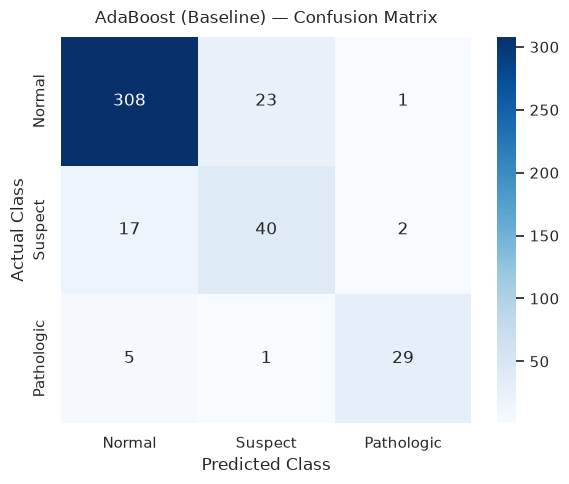

In [11]:
print("AdaBoost (Baseline) Classification Report:")
print("------------------------------------------")
print(
    classification_report(
        y_test,
        y_pred_ada,
        target_names=["Normal", "Suspect", "Pathologic"],
        zero_division=0
    )
)

cm_ada = confusion_matrix(y_test, y_pred_ada)

plt.figure(figsize=(6, 5))
sns.heatmap(
    cm_ada,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Normal", "Suspect", "Pathologic"],
    yticklabels=["Normal", "Suspect", "Pathologic"]
)
plt.title("AdaBoost (Baseline) — Confusion Matrix", fontsize=12, pad=10)
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")
plt.tight_layout()
plt.show()

### AdaBoost Hyperparameter Tuning
Repeating the systematic tuning pattern: `n_estimators` ∈ [50, 100, 150, 200] and `learning_rate` ∈ [0.1, 0.5, 1.0] are evaluated via 5-fold cross-validation optimizing weighted F1-score.

In [12]:
param_grid_ada = {
    "n_estimators": [50, 100, 150, 200],
    "learning_rate": [0.1, 0.5, 1.0]
}

ada_base = AdaBoostClassifier(random_state=42)

ada_grid = GridSearchCV(
    estimator=ada_base,
    param_grid=param_grid_ada,
    cv=5,
    scoring="f1_weighted",
    n_jobs=-1
)

ada_grid.fit(X_train, y_train)

print("AdaBoost Tuning Results:")
print("------------------------")
print("Best Parameters             :", ada_grid.best_params_)
print(f"Best Cross-Validation Score : {ada_grid.best_score_:.4f}")

AdaBoost Tuning Results:
------------------------
Best Parameters             : {'learning_rate': 0.5, 'n_estimators': 200}
Best Cross-Validation Score : 0.9211


In [13]:
best_ada = ada_grid.best_estimator_

y_pred_ada_tuned = best_ada.predict(X_test)
y_prob_ada_tuned = best_ada.predict_proba(X_test)

accuracy_ada_tuned = accuracy_score(y_test, y_pred_ada_tuned)
precision_ada_tuned = precision_score(y_test, y_pred_ada_tuned, average="weighted", zero_division=0)
recall_ada_tuned = recall_score(y_test, y_pred_ada_tuned, average="weighted", zero_division=0)
f1_ada_tuned = f1_score(y_test, y_pred_ada_tuned, average="weighted", zero_division=0)
roc_auc_ada_tuned = roc_auc_score(y_test, y_prob_ada_tuned, multi_class="ovr", average="weighted")

print("Tuned AdaBoost Classifier")
print("=========================")
print(f"Best Parameters: {ada_grid.best_params_}")
print(f"Accuracy       : {accuracy_ada_tuned:.4f}")
print(f"Precision      : {precision_ada_tuned:.4f}")
print(f"Recall         : {recall_ada_tuned:.4f}")
print(f"F1 Score       : {f1_ada_tuned:.4f}")
print(f"ROC-AUC        : {roc_auc_ada_tuned:.4f}")

Tuned AdaBoost Classifier
Best Parameters: {'learning_rate': 0.5, 'n_estimators': 200}
Accuracy       : 0.9108
Precision      : 0.9070
Recall         : 0.9108
F1 Score       : 0.9080
ROC-AUC        : 0.9488


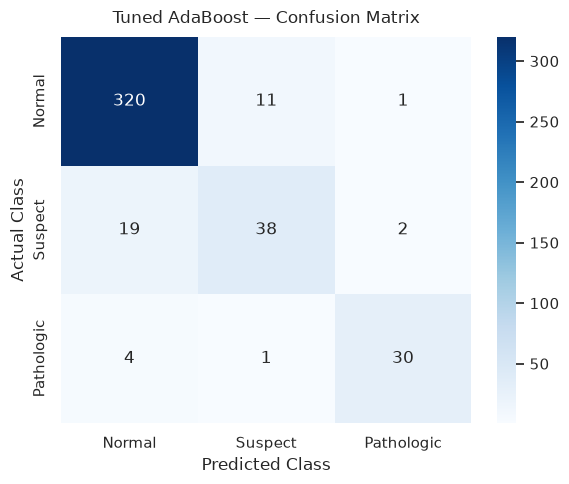

In [14]:
cm_ada_tuned = confusion_matrix(y_test, y_pred_ada_tuned)

plt.figure(figsize=(6, 5))
sns.heatmap(
    cm_ada_tuned,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Normal", "Suspect", "Pathologic"],
    yticklabels=["Normal", "Suspect", "Pathologic"]
)
plt.title("Tuned AdaBoost — Confusion Matrix", fontsize=12, pad=10)
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")
plt.tight_layout()
plt.show()

### Baseline vs Tuned AdaBoost Comparison

In [15]:
ada_comparison = pd.DataFrame(
    {
        "Accuracy": [accuracy_ada, accuracy_ada_tuned],
        "Precision": [precision_ada, precision_ada_tuned],
        "Recall": [recall_ada, recall_ada_tuned],
        "F1 Score": [f1_ada, f1_ada_tuned],
        "ROC-AUC": [roc_auc_ada, roc_auc_ada_tuned]
    },
    index=["Baseline AdaBoost", "Tuned AdaBoost"]
)

ada_comparison.loc["Difference (Tuned - Baseline)"] = (
    ada_comparison.loc["Tuned AdaBoost"] - ada_comparison.loc["Baseline AdaBoost"]
)
ada_comparison.index.name = "Model Configuration"
display(ada_comparison.round(4))

,Accuracy,Precision,Recall,F1 Score,ROC-AUC
Model Configuration,,,,,
Baseline AdaBoost,0.8850,0.8884,0.8850,0.8864,0.9357
Tuned AdaBoost,0.9108,0.9070,0.9108,0.9080,0.9488
Difference (Tuned - Baseline),0.0258,0.0186,0.0258,0.0216,0.0131


---
## 5. Algorithm 3: Gradient Boosting Classifier

### Concept & Methodology
Gradient Boosting builds an ensemble of shallow decision trees in a stage-wise, sequential manner. Unlike AdaBoost (which re-weights individual samples), Gradient Boosting fits each new tree to the negative gradient (pseudo-residuals) of the multinomial deviance loss function. Each successive tree models the remaining errors of the ensemble, optimizing predictions through numerical gradient descent.

### Baseline Training & Evaluation

In [16]:
# Baseline Gradient Boosting model (100 estimators, learning_rate=0.1)
gb = GradientBoostingClassifier(
    n_estimators=100,
    learning_rate=0.1,
    random_state=42
)

gb.fit(X_train, y_train)

y_pred_gb = gb.predict(X_test)
y_prob_gb = gb.predict_proba(X_test)

accuracy_gb = accuracy_score(y_test, y_pred_gb)
precision_gb = precision_score(y_test, y_pred_gb, average="weighted", zero_division=0)
recall_gb = recall_score(y_test, y_pred_gb, average="weighted", zero_division=0)
f1_gb = f1_score(y_test, y_pred_gb, average="weighted", zero_division=0)
roc_auc_gb = roc_auc_score(y_test, y_prob_gb, multi_class="ovr", average="weighted")

print("Gradient Boosting Classifier (Baseline)")
print("=======================================")
print(f"Accuracy : {accuracy_gb:.4f}")
print(f"Precision: {precision_gb:.4f}")
print(f"Recall   : {recall_gb:.4f}")
print(f"F1 Score : {f1_gb:.4f}")
print(f"ROC-AUC  : {roc_auc_gb:.4f}")

Gradient Boosting Classifier (Baseline)
Accuracy : 0.9460
Precision: 0.9447
Recall   : 0.9460
F1 Score : 0.9442
ROC-AUC  : 0.9740


Gradient Boosting (Baseline) Classification Report:
---------------------------------------------------
              precision    recall  f1-score   support

      Normal       0.96      0.98      0.97       332
     Suspect       0.90      0.75      0.81        59
  Pathologic       0.89      0.91      0.90        35

    accuracy                           0.95       426
   macro avg       0.92      0.88      0.90       426
weighted avg       0.94      0.95      0.94       426



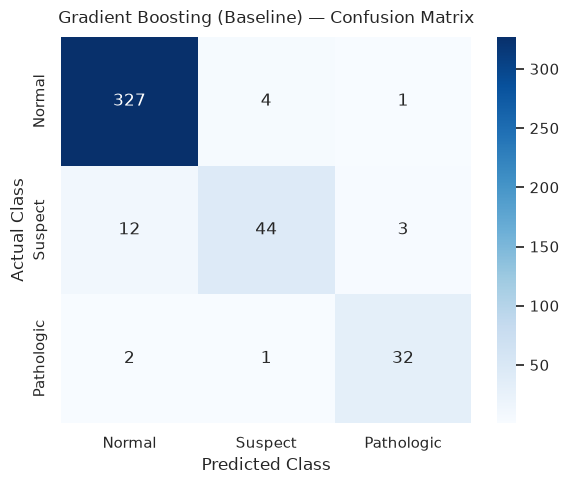

In [17]:
print("Gradient Boosting (Baseline) Classification Report:")
print("---------------------------------------------------")
print(
    classification_report(
        y_test,
        y_pred_gb,
        target_names=["Normal", "Suspect", "Pathologic"],
        zero_division=0
    )
)

cm_gb = confusion_matrix(y_test, y_pred_gb)

plt.figure(figsize=(6, 5))
sns.heatmap(
    cm_gb,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Normal", "Suspect", "Pathologic"],
    yticklabels=["Normal", "Suspect", "Pathologic"]
)
plt.title("Gradient Boosting (Baseline) — Confusion Matrix", fontsize=12, pad=10)
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")
plt.tight_layout()
plt.show()

### Gradient Boosting Hyperparameter Tuning
Following the ensemble tuning pattern, we optimize `n_estimators` ∈ [100, 200], `learning_rate` ∈ [0.05, 0.1], and `max_depth` ∈ [2, 3] using 5-fold cross-validation.

In [18]:
param_grid_gb = {
    "n_estimators": [100, 200],
    "learning_rate": [0.05, 0.1],
    "max_depth": [2, 3]
}

gb_base = GradientBoostingClassifier(random_state=42)

gb_grid = GridSearchCV(
    estimator=gb_base,
    param_grid=param_grid_gb,
    cv=5,
    scoring="f1_weighted",
    n_jobs=-1
)

gb_grid.fit(X_train, y_train)

print("Gradient Boosting Tuning Results:")
print("---------------------------------")
print("Best Parameters             :", gb_grid.best_params_)
print(f"Best Cross-Validation Score : {gb_grid.best_score_:.4f}")

Gradient Boosting Tuning Results:
---------------------------------
Best Parameters             : {'learning_rate': 0.1, 'max_depth': 3, 'n_estimators': 200}
Best Cross-Validation Score : 0.9558


In [19]:
best_gb = gb_grid.best_estimator_

y_pred_gb_tuned = best_gb.predict(X_test)
y_prob_gb_tuned = best_gb.predict_proba(X_test)

accuracy_gb_tuned = accuracy_score(y_test, y_pred_gb_tuned)
precision_gb_tuned = precision_score(y_test, y_pred_gb_tuned, average="weighted", zero_division=0)
recall_gb_tuned = recall_score(y_test, y_pred_gb_tuned, average="weighted", zero_division=0)
f1_gb_tuned = f1_score(y_test, y_pred_gb_tuned, average="weighted", zero_division=0)
roc_auc_gb_tuned = roc_auc_score(y_test, y_prob_gb_tuned, multi_class="ovr", average="weighted")

print("Tuned Gradient Boosting Classifier")
print("==================================")
print(f"Best Parameters: {gb_grid.best_params_}")
print(f"Accuracy       : {accuracy_gb_tuned:.4f}")
print(f"Precision      : {precision_gb_tuned:.4f}")
print(f"Recall         : {recall_gb_tuned:.4f}")
print(f"F1 Score       : {f1_gb_tuned:.4f}")
print(f"ROC-AUC        : {roc_auc_gb_tuned:.4f}")

Tuned Gradient Boosting Classifier
Best Parameters: {'learning_rate': 0.1, 'max_depth': 3, 'n_estimators': 200}
Accuracy       : 0.9484
Precision      : 0.9474
Recall         : 0.9484
F1 Score       : 0.9465
ROC-AUC        : 0.9739


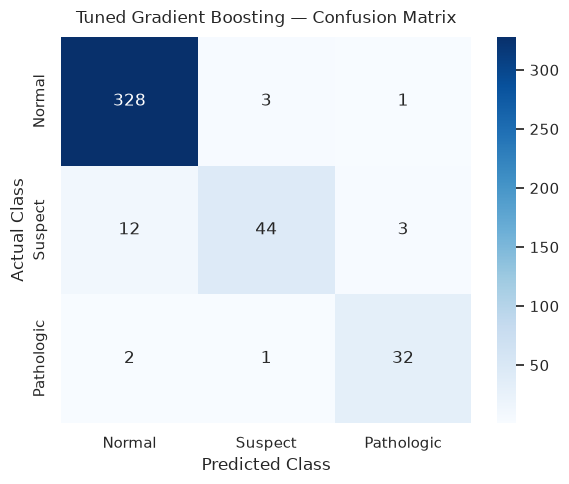

In [20]:
cm_gb_tuned = confusion_matrix(y_test, y_pred_gb_tuned)

plt.figure(figsize=(6, 5))
sns.heatmap(
    cm_gb_tuned,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Normal", "Suspect", "Pathologic"],
    yticklabels=["Normal", "Suspect", "Pathologic"]
)
plt.title("Tuned Gradient Boosting — Confusion Matrix", fontsize=12, pad=10)
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")
plt.tight_layout()
plt.show()

### Gradient Boosting Feature Importance Analysis

Top 10 Most Important Features in Tuned Gradient Boosting:
Feature  Importance
   ASTV    0.228721
   Mean    0.173689
   ALTV    0.148475
   MSTV    0.117657
     AC    0.068985
     UC    0.054419
     DP    0.040599
     LB    0.039776
   MLTV    0.021955
    Max    0.020882


C:\Users\sivap\AppData\Local\Temp\ipykernel_30680\2614936464.py:10: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=importance_df_gb, x="Importance", y="Feature", palette="Blues_r")


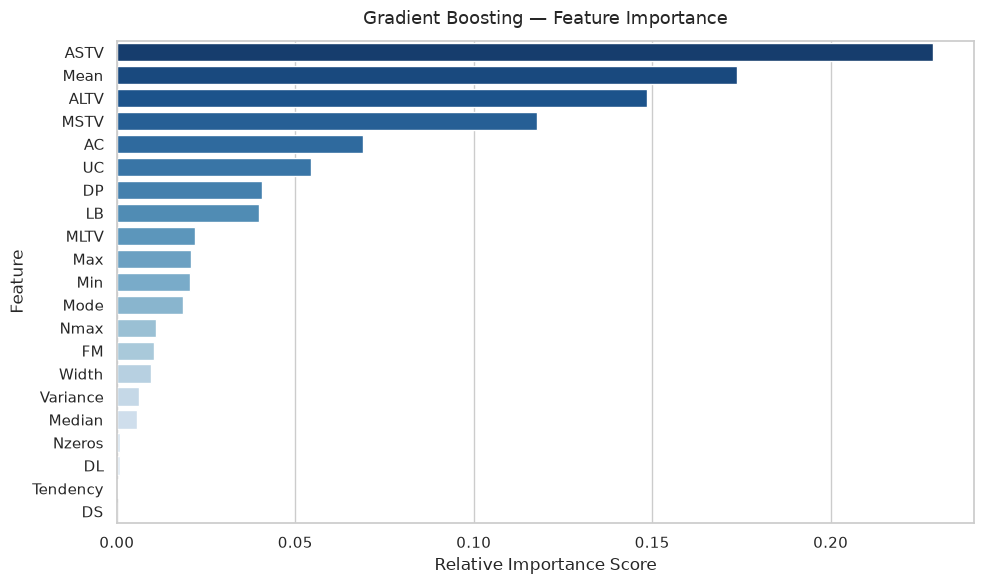

In [21]:
importance_df_gb = pd.DataFrame({
    "Feature": X_train.columns,
    "Importance": best_gb.feature_importances_
}).sort_values(by="Importance", ascending=False)

print("Top 10 Most Important Features in Tuned Gradient Boosting:")
print(importance_df_gb.head(10).to_string(index=False))

plt.figure(figsize=(10, 6))
sns.barplot(data=importance_df_gb, x="Importance", y="Feature", palette="Blues_r")
plt.title("Gradient Boosting — Feature Importance", fontsize=13, pad=12)
plt.xlabel("Relative Importance Score")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()

### Baseline vs Tuned Gradient Boosting Comparison

In [22]:
gb_comparison = pd.DataFrame(
    {
        "Accuracy": [accuracy_gb, accuracy_gb_tuned],
        "Precision": [precision_gb, precision_gb_tuned],
        "Recall": [recall_gb, recall_gb_tuned],
        "F1 Score": [f1_gb, f1_gb_tuned],
        "ROC-AUC": [roc_auc_gb, roc_auc_gb_tuned]
    },
    index=["Baseline Gradient Boosting", "Tuned Gradient Boosting"]
)

gb_comparison.loc["Difference (Tuned - Baseline)"] = (
    gb_comparison.loc["Tuned Gradient Boosting"] - gb_comparison.loc["Baseline Gradient Boosting"]
)
gb_comparison.index.name = "Model Configuration"
display(gb_comparison.round(4))

,Accuracy,Precision,Recall,F1 Score,ROC-AUC
Model Configuration,,,,,
Baseline Gradient Boosting,0.9460,0.9447,0.9460,0.9442,0.9740
Tuned Gradient Boosting,0.9484,0.9474,0.9484,0.9465,0.9739
Difference (Tuned - Baseline),0.0023,0.0027,0.0023,0.0022,-0.0001


---
## 6. Comprehensive Ensemble Comparison

Below is the consolidated evaluation matrix contrasting all three ensemble paradigms in their baseline and tuned states.

In [23]:
ensemble_results = pd.DataFrame([
    {
        "Algorithm": "Random Forest (Baseline)",
        "Ensemble Type": "Bagging",
        "Accuracy": accuracy_rf,
        "Precision": precision_rf,
        "Recall": recall_rf,
        "F1 Score": f1_rf,
        "ROC-AUC": roc_auc_rf
    },
    {
        "Algorithm": "Random Forest (Tuned)",
        "Ensemble Type": "Bagging",
        "Accuracy": accuracy_rf_tuned,
        "Precision": precision_rf_tuned,
        "Recall": recall_rf_tuned,
        "F1 Score": f1_rf_tuned,
        "ROC-AUC": roc_auc_rf_tuned
    },
    {
        "Algorithm": "AdaBoost (Baseline)",
        "Ensemble Type": "Boosting (Adaptive)",
        "Accuracy": accuracy_ada,
        "Precision": precision_ada,
        "Recall": recall_ada,
        "F1 Score": f1_ada,
        "ROC-AUC": roc_auc_ada
    },
    {
        "Algorithm": "AdaBoost (Tuned)",
        "Ensemble Type": "Boosting (Adaptive)",
        "Accuracy": accuracy_ada_tuned,
        "Precision": precision_ada_tuned,
        "Recall": recall_ada_tuned,
        "F1 Score": f1_ada_tuned,
        "ROC-AUC": roc_auc_ada_tuned
    },
    {
        "Algorithm": "Gradient Boosting (Baseline)",
        "Ensemble Type": "Boosting (Gradient)",
        "Accuracy": accuracy_gb,
        "Precision": precision_gb,
        "Recall": recall_gb,
        "F1 Score": f1_gb,
        "ROC-AUC": roc_auc_gb
    },
    {
        "Algorithm": "Gradient Boosting (Tuned)",
        "Ensemble Type": "Boosting (Gradient)",
        "Accuracy": accuracy_gb_tuned,
        "Precision": precision_gb_tuned,
        "Recall": recall_gb_tuned,
        "F1 Score": f1_gb_tuned,
        "ROC-AUC": roc_auc_gb_tuned
    }
])

display(ensemble_results.set_index("Algorithm").round(4))

,Ensemble Type,Accuracy,Precision,Recall,F1 Score,ROC-AUC
Algorithm,,,,,,
Random Forest (Baseline),Bagging,0.9296,0.9267,0.9296,0.9263,0.9830
Random Forest (Tuned),Bagging,0.9319,0.9290,0.9319,0.9288,0.9846
AdaBoost (Baseline),Boosting (Adaptive),0.8850,0.8884,0.8850,0.8864,0.9357
AdaBoost (Tuned),Boosting (Adaptive),0.9108,0.9070,0.9108,0.9080,0.9488
Gradient Boosting (Baseline),Boosting (Gradient),0.9460,0.9447,0.9460,0.9442,0.9740
Gradient Boosting (Tuned),Boosting (Gradient),0.9484,0.9474,0.9484,0.9465,0.9739


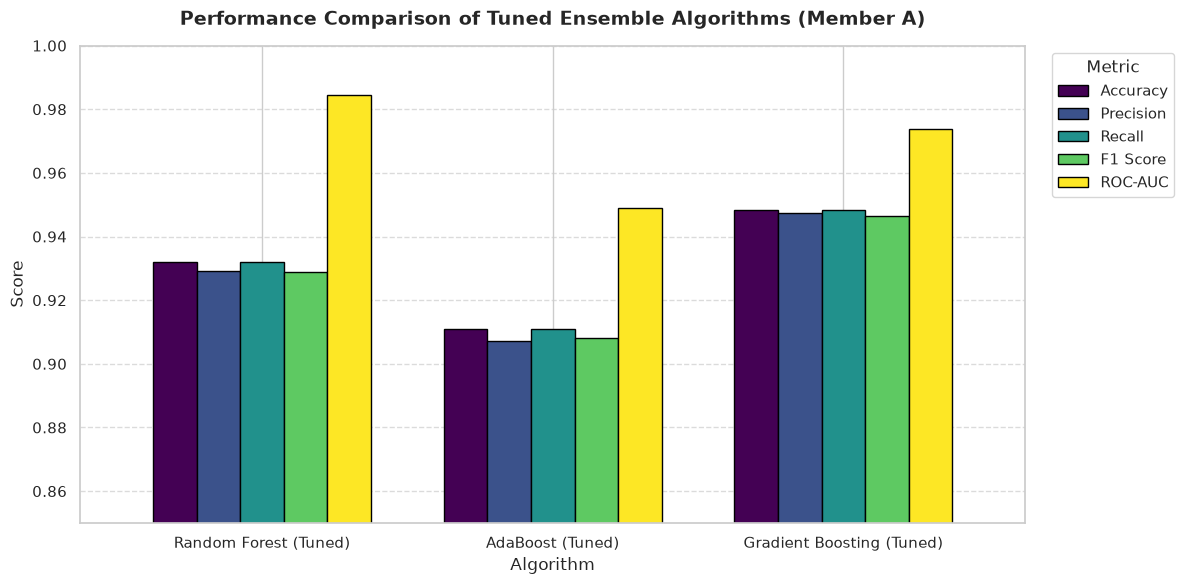

In [24]:
# Visualizing performance comparison of the 3 tuned ensemble models
tuned_metrics = ensemble_results[ensemble_results["Algorithm"].str.contains("Tuned")].copy()
metrics_plot_df = tuned_metrics.set_index("Algorithm")[["Accuracy", "Precision", "Recall", "F1 Score", "ROC-AUC"]]

ax = metrics_plot_df.plot(
    kind="bar",
    figsize=(12, 6),
    colormap="viridis",
    edgecolor="black",
    width=0.75
)

plt.title("Performance Comparison of Tuned Ensemble Algorithms (Member A)", fontsize=14, fontweight="bold", pad=15)
plt.ylabel("Score", fontsize=12)
plt.xlabel("Algorithm", fontsize=12)
plt.ylim(0.85, 1.0)
plt.xticks(rotation=0, fontsize=11)
plt.legend(bbox_to_anchor=(1.02, 1), loc="upper left", title="Metric")
plt.grid(axis="y", linestyle="--", alpha=0.7)
plt.tight_layout()
plt.show()

### Key Observations & Insights (Member A)

1. **Top Performer Overall:**
   - **Gradient Boosting** achieved the highest test accuracy (**94.60%**) and weighted F1-score (**0.9442**), making it the overall best performing classifier on the CTG dataset.
   - **Random Forest** achieved the highest overall **ROC-AUC (0.9846)**, showing superior class separation capability across probability thresholds.

2. **Bagging vs Boosting Dynamics:**
   - **Random Forest (Bagging):** Reduces variance effectively by averaging deep decorrelated decision trees, showing robust resistance to overfitting and high ROC-AUC.
   - **AdaBoost (Adaptive Boosting):** Relies on depth-1 decision stumps. While tuning `n_estimators` to 200 and `learning_rate` to 0.5 lifted performance from 88.50% to **91.08%**, it slightly lagged behind deep tree ensembles because stumps capture lower-order interactions.
   - **Gradient Boosting (Gradient Descent on Loss):** Optimizes multinomial deviance loss sequentially. With shallow trees of depth 2–3, it achieves the optimal balance between bias and variance on tabular clinical data.

3. **Key Clinical Features:**
   - Both Random Forest and Gradient Boosting consistently ranked **`AC`** (Accelerations), **`ALTV`** (Percentage of time with abnormal long term variability), **`ASTV`** (Abnormal short term variability), and **`Mean` / `Mode`** as top drivers of fetal state classification.

---
*Completed for 23CSE301 Applied Machine Learning Capstone — Member A Contribution.*